# Evaluación 3 — Modelado predictivo de riesgo crediticio (Clasificación)

**Grupo:** Juan Riquelme, Yoseph Rodríguez, Andrew Sepúlveda, Felipe Soto

**Fecha de entrega:** 05 de noviembre de 2026  

---

## Contexto del negocio

Una institución financiera recibe solicitudes de **créditos hipotecarios** y necesita anticipar si un cliente caerá en **impago** (`Riesgo_Impago = 1`) o cumplirá (`Riesgo_Impago = 0`).

Los errores del modelo **no cuestan lo mismo**:

| Error | Qué ocurre | Costo por caso |
|---|---|---|
| **Falso Negativo (FN)** | Se aprueba el crédito a un cliente que luego **no paga** | **\$1.500.000** (pérdida directa de capital) |
| **Falso Positivo (FP)** | Se **rechaza** a un cliente que sí habría pagado | **\$200.000** (costo de oportunidad: intereses no ganados) |

Un FN es **7,5 veces más caro** que un FP. Esto condiciona la elección de métricas, la optimización de hiperparámetros y la interpretación de resultados.

## Objetivo

Construir y comparar un **modelo base** y un **modelo optimizado** (`DecisionTreeClassifier`) que identifiquen clientes en riesgo de impago, usando un **Pipeline de Scikit-Learn** (sin fuga de datos) y evaluando sobre un conjunto de prueba nunca visto.

## Hoja de ruta

| Fase | Herramienta | Objetivo |
|---|---|---|
| 1 | EDA (`info`, `describe`, gráficos) | Diagnosticar calidad: nulos, tipos, inconsistencias lógicas, outliers, desbalance |
| 2 | `Pipeline` + `ColumnTransformer` | Limpieza reproducible y **sin data leakage** |
| 3 | `train_test_split(stratify=y)`, `DecisionTreeClassifier`, `GridSearchCV` | Línea base y modelo optimizado (≥ 4 hiperparámetros) |
| 4 | Métricas, matriz de confusión, costo, train vs test | Evaluación sobre test e interpretación financiera |

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")

# Semilla ÚNICA: se usa en el split, en los modelos, en la validación cruzada y en GridSearchCV
RANDOM_STATE = 29

# Costos de negocio informados en el enunciado (CLP/USD según la institución; solo importa la proporción)
COSTO_FN = 1_500_000   # crédito otorgado que termina en impago
COSTO_FP = 200_000     # crédito viable que se deniega

TARGET = "Riesgo_Impago"
target_names = ["Cumplidor", "Impago"]

---
# Fase 1 — Diagnóstico y calidad de datos (EDA)

## 1.1 Carga del dataset

In [4]:
!wget https://raw.githubusercontent.com/JRiquelmeP/EVALUACIONES-IA-2026-02/main/E3-Clasificaci%C3%B3n/riesgo_crediticio.csv

data = pd.read_csv("riesgo_crediticio.csv")
print(f"Dimensiones: {data.shape[0]:,} filas x {data.shape[1]} columnas")
data.head()

--2026-11-05 22:26:16--  https://raw.githubusercontent.com/JRiquelmeP/EVALUACIONES-IA-2026-02/main/E3-Clasificaci%C3%B3n/riesgo_crediticio.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 953627 (931K) [text/plain]
Saving to: ‘riesgo_crediticio.csv.1’

riesgo_crediticio.c 100%[===================>] 931.28K  --.-KB/s    in 0.1s    

2026-11-05 22:26:17 (7.90 MB/s) - ‘riesgo_crediticio.csv.1’ saved [953627/953627]

Dimensiones: 25,000 filas x 6 columnas


,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,39785.55,85246.38,694.0,70.00,0
1,1,69773.95,244260.00,622.0,10.65,0
2,2,127770.68,209310.35,780.0,42.70,0
3,3,16799.80,213059.98,741.0,48.04,0
4,4,70229.83,219523.13,714.0,25.58,0


**Observación:** la primera columna `Unnamed: 0` es el **índice de fila** que quedó guardado al exportar el CSV; no es una variable del negocio (no aparece en el diccionario de datos). Verificamos que no tenga relación con el target antes de eliminarla.

In [5]:
corr_indice = data["Unnamed: 0"].corr(data[TARGET])
print(f"Correlación de 'Unnamed: 0' con {TARGET}: {corr_indice:.4f}")
print(f"¿Es un índice secuencial 0..n-1? {data['Unnamed: 0'].equals(pd.Series(range(len(data))))}")

# Se elimina: es un identificador sin valor predictivo y, si el archivo viniera ordenado,
# podría introducir una señal artificial (riesgo de leakage).
data = data.drop(columns=["Unnamed: 0"])
data.columns.tolist()

Correlación de 'Unnamed: 0' con Riesgo_Impago: -0.0059
¿Es un índice secuencial 0..n-1? True


['Ingreso_Anual',
 'Monto_Prestamo',
 'Puntaje_Credito',
 'Relacion_Deuda_Ingreso',
 'Riesgo_Impago']

## 1.2 Tipos de datos, nulos y duplicados

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Ingreso_Anual           25000 non-null  float64
 1   Monto_Prestamo          25000 non-null  float64
 2   Puntaje_Credito         25000 non-null  float64
 3   Relacion_Deuda_Ingreso  25000 non-null  float64
 4   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(1)
memory usage: 976.7 KB


In [7]:
calidad = pd.DataFrame({
    "tipo": data.dtypes,
    "nulos": data.isna().sum(),
    "% nulos": (data.isna().mean() * 100).round(2),
    "valores únicos": data.nunique(),
})
display(calidad)
print(f"Filas duplicadas: {data.duplicated().sum()}")

,tipo,nulos,% nulos,valores únicos
Ingreso_Anual,float64,0,0.0,24970
Monto_Prestamo,float64,0,0.0,24927
Puntaje_Credito,float64,0,0.0,373
Relacion_Deuda_Ingreso,float64,0,0.0,5109
Riesgo_Impago,int64,0,0.0,2


Filas duplicadas: 0


**Lectura:** las 5 columnas son numéricas (4 `float64` + el target entero), **no hay valores nulos ni filas duplicadas**. No existen variables categóricas, por lo que **no se necesita codificación (One-Hot)**.

Aun sin nulos, el pipeline incluirá un imputador: los datos reales de una institución financiera pueden llegar con vacíos en producción, y el pipeline debe ser reutilizable.

## 1.3 Estadísticos descriptivos e inconsistencias lógicas

In [8]:
display(data.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,25000.0,55824.44,29804.90,7832.12,35051.32,49234.68,68923.52,348135.55
Monto_Prestamo,25000.0,220162.89,60059.30,50000.00,179438.08,220241.47,261003.36,451784.21
Puntaje_Credito,25000.0,680.03,59.78,457.00,640.00,680.00,721.00,850.00
Relacion_Deuda_Ingreso,25000.0,24.03,13.62,5.00,13.79,21.45,31.38,70.00
Riesgo_Impago,25000.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00


In [9]:
# Reglas de coherencia del negocio (según el diccionario de datos)
reglas = {
    "Ingreso_Anual <= 0": (data["Ingreso_Anual"] <= 0).sum(),
    "Monto_Prestamo <= 0": (data["Monto_Prestamo"] <= 0).sum(),
    "Puntaje_Credito fuera de [300, 850]": ((data["Puntaje_Credito"] < 300) | (data["Puntaje_Credito"] > 850)).sum(),
    "Relacion_Deuda_Ingreso < 0 o > 100": ((data["Relacion_Deuda_Ingreso"] < 0) | (data["Relacion_Deuda_Ingreso"] > 100)).sum(),
    f"{TARGET} distinto de 0/1": (~data[TARGET].isin([0, 1])).sum(),
}
display(pd.Series(reglas, name="Registros que violan la regla").to_frame())

# Relación préstamo/ingreso (referencia de plausibilidad económica)
ratio = data["Monto_Prestamo"] / data["Ingreso_Anual"]
print("Monto_Prestamo / Ingreso_Anual (veces el ingreso anual):")
print(ratio.describe().round(2).to_string())

,Registros que violan la regla
Ingreso_Anual <= 0,0
Monto_Prestamo <= 0,0
"Puntaje_Credito fuera de [300, 850]",0
Relacion_Deuda_Ingreso < 0 o > 100,0
Riesgo_Impago distinto de 0/1,0


Monto_Prestamo / Ingreso_Anual (veces el ingreso anual):
count    25000.00
mean         5.07
std          3.15
min          0.34
25%          2.94
50%          4.34
75%          6.37
max         42.65


**Lectura:** **ninguna regla lógica se viola** (no hay ingresos/montos ≤ 0, el puntaje está dentro de 300–850 y el DTI dentro de 0–100 %). Hay solicitudes cuyo monto supera 40 veces el ingreso anual: es inusual pero **no imposible** en hipotecas, y **no se eliminan filas**; se tratarán con winsorización (ver 1.5).

## 1.4 Variable objetivo: desbalance de clases

,clientes,proporción
Cumplidor,NaN,NaN
Impago,NaN,NaN


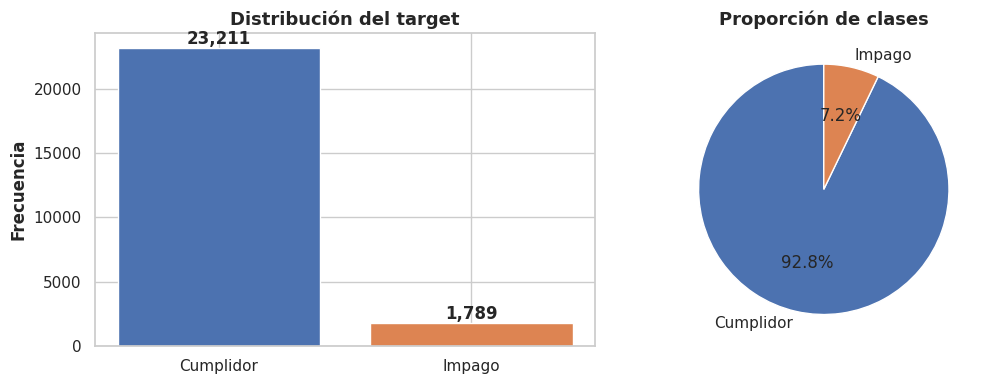

Razón de desbalance: 13.0 cumplidores por cada impago
Accuracy de un 'modelo tonto' que aprueba a todos: 92.84%


In [10]:
conteo = data[TARGET].value_counts().sort_index()
prop = data[TARGET].value_counts(normalize=True).sort_index()
display(pd.DataFrame({"clientes": conteo, "proporción": prop.round(4)}, index=target_names))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
colores = ["#4C72B0", "#DD8452"]
ax[0].bar(target_names, conteo.values, color=colores)
for i, v in enumerate(conteo.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontweight="bold")
ax[0].set_title("Distribución del target", fontsize=13, fontweight="bold")
ax[0].set_ylabel("Frecuencia", fontweight="bold")
ax[1].pie(conteo.values, labels=target_names, autopct="%1.1f%%", colors=colores, startangle=90)
ax[1].set_title("Proporción de clases", fontsize=13, fontweight="bold")
plt.tight_layout(); plt.show()

print(f"Razón de desbalance: {conteo[0] / conteo[1]:.1f} cumplidores por cada impago")
print(f"Accuracy de un 'modelo tonto' que aprueba a todos: {prop[0]:.2%}")

**Hallazgo clave:** solo **7.16 %** de los clientes cae en impago (≈ 13 a 1). Un modelo que apruebe a todos tendría un *accuracy* de **92.8 %** sin detectar ni un solo impago, lo que implicaría la mayor pérdida posible. Por lo tanto:

1. El **accuracy no sirve** como métrica principal.
2. Se debe **estratificar** el split train/test y la validación cruzada para conservar la proporción de la clase minoritaria.
3. Conviene evaluar el uso de `class_weight="balanced"` en el árbol (se incluirá como hiperparámetro a optimizar).

## 1.5 Distribución y valores atípicos (outliers)

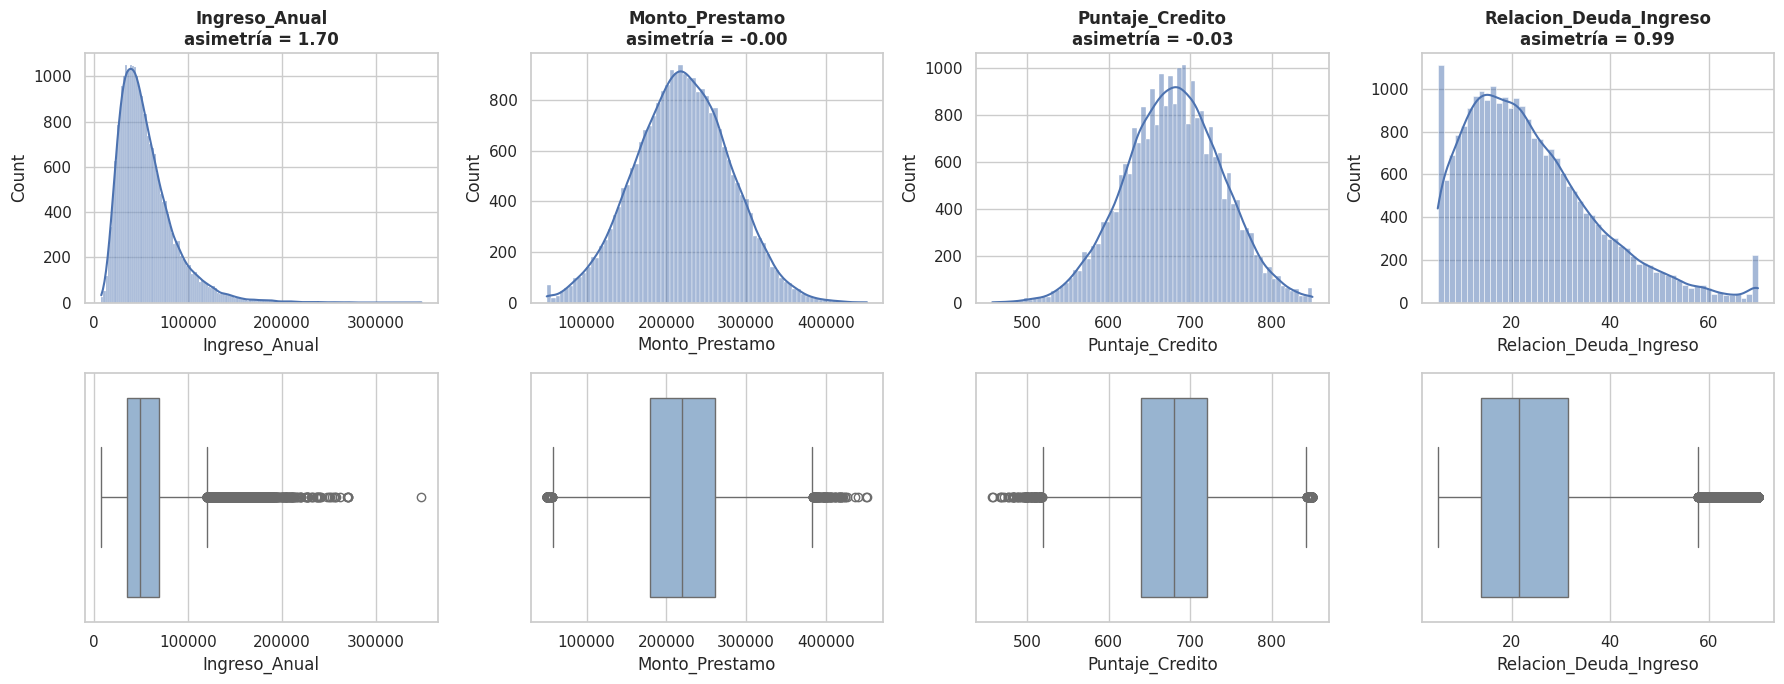

In [11]:
features = ["Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito", "Relacion_Deuda_Ingreso"]

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, col in enumerate(features):
    sns.histplot(data[col], kde=True, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"{col}\nasimetría = {data[col].skew():.2f}", fontweight="bold")
    sns.boxplot(x=data[col], ax=axes[1, i], color="#8FB4D9")
plt.tight_layout(); plt.show()

In [12]:
# Outliers según regla del rango intercuartílico (1.5 x IQR) y percentiles extremos
filas = []
for col in features:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, up = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((data[col] < low) | (data[col] > up)).sum()
    filas.append({"variable": col, "outliers (IQR)": n_out, "% filas": round(100 * n_out / len(data), 2),
                  "p1": data[col].quantile(0.01), "p99": data[col].quantile(0.99), "máximo": data[col].max()})
display(pd.DataFrame(filas).set_index("variable").round(2))

,outliers (IQR),% filas,p1,p99,máximo
variable,,,,,
Ingreso_Anual,976,3.90,15401.57,159086.03,348135.55
Monto_Prestamo,157,0.63,80701.96,358870.85,451784.21
Puntaje_Credito,167,0.67,542.00,819.00,850.00
Relacion_Deuda_Ingreso,663,2.65,5.00,68.09,70.00


DTI == 5.0 (mínimo): 631 registros (2.52%)
DTI == 70.0 (máximo): 196 registros (0.78%)


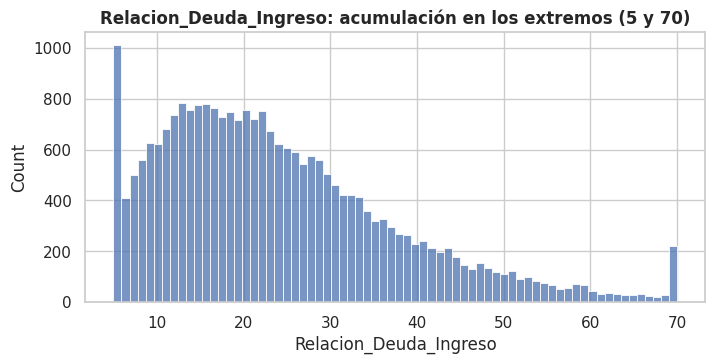

In [13]:
# Apilamiento de valores en Relacion_Deuda_Ingreso (posible tope / censura en la captura)
dti = data["Relacion_Deuda_Ingreso"]
print(f"DTI == 5.0 (mínimo): {(dti == dti.min()).sum()} registros ({(dti == dti.min()).mean():.2%})")
print(f"DTI == 70.0 (máximo): {(dti == dti.max()).sum()} registros ({(dti == dti.max()).mean():.2%})")

plt.figure(figsize=(8, 3.5))
sns.histplot(dti, bins=70, color="#4C72B0")
plt.title("Relacion_Deuda_Ingreso: acumulación en los extremos (5 y 70)", fontweight="bold")
plt.show()

**Hallazgos:**
- `Ingreso_Anual` presenta **asimetría positiva marcada** (1.70) y outliers a la derecha (máximo ≈ \$348,136 frente a un p99 ≈ \$159,086): pocos clientes de ingresos muy altos.
- `Relacion_Deuda_Ingreso` también es asimétrica y tiene **valores apilados en 5 % y 70 %**, señal de que la variable fue **acotada (censurada)** en origen. Lo documentamos como limitación: no se pueden distinguir clientes con DTI real menor a 5 % o mayor a 70 %.
- `Monto_Prestamo` y `Puntaje_Credito` son aproximadamente simétricas, con pocos atípicos.

**Decisión de tratamiento:** los outliers son **valores reales y plausibles** (no errores de captura), por lo que **no se eliminan**; se **winsorizan al 1 % - 99 %** dentro del pipeline. Esto acota los valores extremos sin perder filas (con 7 % de impagos, cada fila de la clase minoritaria es valiosa). Como el modelo es un árbol (decide por umbrales y es poco sensible a valores extremos), el efecto esperado es pequeño; en la sección 3.3 se verifica con los datos si cambia o no el desempeño.

## 1.6 Relación de las variables con el riesgo de impago

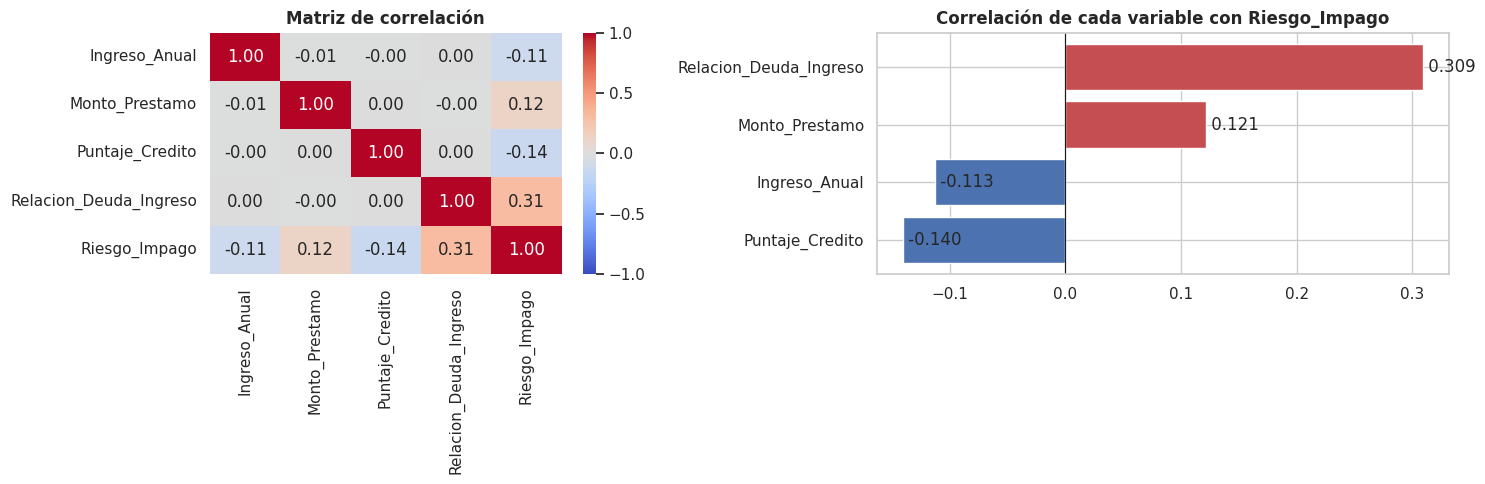

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.3]})

corr = data.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Matriz de correlación", fontweight="bold")

corr_t = corr[[TARGET]].drop(TARGET).sort_values(TARGET)
axes[1].barh(corr_t.index, corr_t[TARGET], color=["#C44E52" if v > 0 else "#4C72B0" for v in corr_t[TARGET]])
axes[1].set_title(f"Correlación de cada variable con {TARGET}", fontweight="bold")
axes[1].axvline(0, color="k", lw=0.8)
for i, v in enumerate(corr_t[TARGET]):
    axes[1].text(v, i, f" {v:.3f}", va="center")
plt.tight_layout(); plt.show()

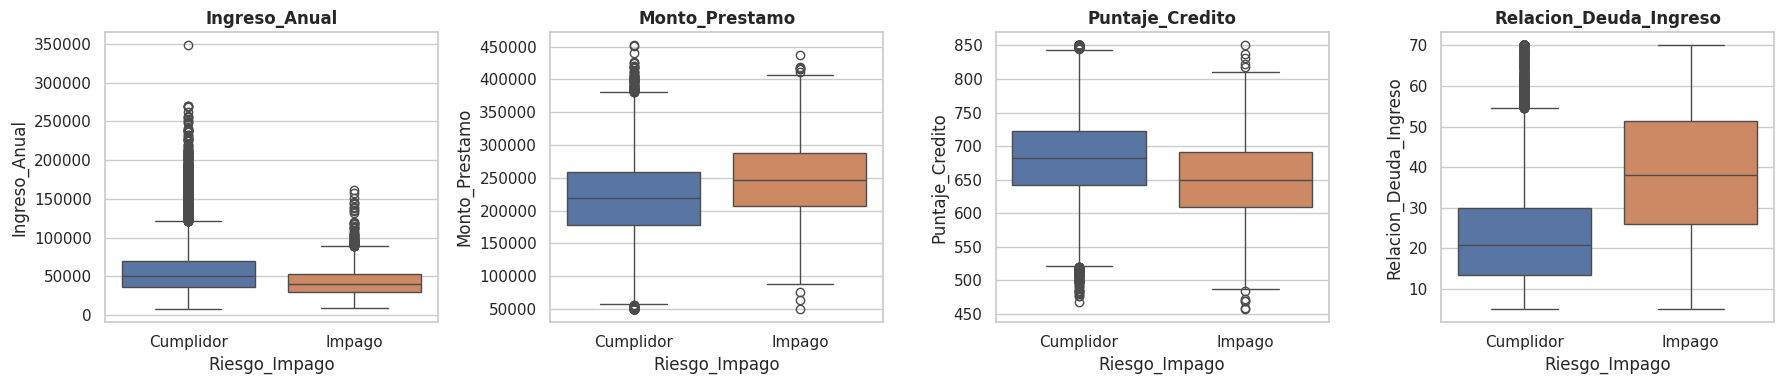

,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso
Riesgo_Impago,,,,
Cumplidor,56757.46,218140.82,682.36,22.86
Impago,43719.24,246397.83,649.85,39.18


In [15]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, features):
    sns.boxplot(data=data, x=TARGET, y=col, hue=TARGET, palette=["#4C72B0", "#DD8452"], legend=False, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(target_names)
    ax.set_title(col, fontweight="bold")
plt.tight_layout(); plt.show()

display(data.groupby(TARGET).mean().round(2).rename(index=dict(enumerate(target_names))))

**Lectura:** la relación es coherente con la lógica financiera y **no hay ninguna variable que "explique" el target de forma sospechosa** (la mayor correlación es Relacion_Deuda_Ingreso (DTI) con 0.31; no hay correlaciones cercanas a ±1), por lo que **no se detectan indicios de data leakage** en las variables predictoras (ninguna variable es una consecuencia directa del impago).
- A **mayor DTI**, mayor probabilidad de impago (clientes impagos: DTI medio 39.2 % vs 22.9 %).
- A **menor puntaje de crédito** y **menor ingreso**, mayor probabilidad de impago.

## 1.7 Resumen del diagnóstico

| Aspecto | Resultado | Decisión |
|---|---|---|
| Nulos | 0 | Se mantiene imputador (mediana) por robustez en producción |
| Duplicados | 0 | Sin acción |
| Tipos | 100 % numéricos | Sin codificación categórica |
| Inconsistencias lógicas | Ninguna | No se eliminan filas |
| Outliers | Ingreso (asimetría fuerte), DTI censurado en 5 y 70 | Winsorización 1 %–99 % |
| Columna `Unnamed: 0` | Índice sin valor predictivo | Se elimina |
| Target | ≈ 7 % impagos (desbalanceado) | Split estratificado, `class_weight`, métricas adecuadas |
| Leakage en variables | No se detecta | Pipeline para evitar leakage en el preprocesamiento |

---
# Fase 2 — Limpieza y tratamiento de datos (Pipeline)

## 2.1 Diseño del pipeline

Todo el tratamiento se encapsula en un **`Pipeline` + `ColumnTransformer`**. Así, **cada transformación se ajusta (`fit`) solo con los datos de entrenamiento** y luego se aplica al conjunto de prueba. Si calculáramos medianas, cuantiles o medias con *todo* el dataset antes de dividir, la información del test "se filtraría" al entrenamiento (**data leakage**) y las métricas quedarían infladas.

| Paso | Justificación |
|---|---|
| `Winsorizer(1 %, 1 %)` | `Ingreso_Anual` tiene asimetría fuerte (máximo ≈ \$348 mil vs p99 ≈ \$159 mil) y `Relacion_Deuda_Ingreso` está acotada en los extremos. Se limitan al p1–p99 sin perder filas. Los límites se calculan **en `fit`** (solo con train) y se reutilizan en `transform`. |
| `SimpleImputer(strategy="median")` | La mediana es robusta a la asimetría observada en `Ingreso_Anual` (la media se distorsionaría). Hoy no hay nulos, pero protege el pipeline si llegan solicitudes con datos faltantes. |
| Escalado | **No se aplica.** El árbol de decisión divide cada variable por umbrales, por lo que su resultado no cambia con la escala. Omitirlo permite leer las reglas del árbol en **unidades reales** (dólares, puntos de score, % de DTI). |
| Codificación categórica | **No aplica**: las 4 variables predictoras son numéricas. |

> **Cálculo de límites en `fit`:** los cuantiles de la winsorización se calculan con los datos de entrenamiento y se guardan. Si se recalcularan al transformar el test, se usarían los cuantiles del propio test (una forma sutil de leakage).

In [16]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Limita (clip) cada columna a los percentiles [limits[0], 1 - limits[1]] aprendidos en fit."""

    def __init__(self, limits=(0.01, 0.01)):
        self.limits = limits

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.columns_ = X.columns
        self.lower_ = X.quantile(self.limits[0])          # límites aprendidos SOLO con los datos de fit
        self.upper_ = X.quantile(1 - self.limits[1])
        return self

    def transform(self, X):
        X = pd.DataFrame(X, columns=self.columns_).copy()
        return X.clip(lower=self.lower_, upper=self.upper_, axis=1).values

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_, dtype=object)


features_num = ["Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito", "Relacion_Deuda_Ingreso"]


def crear_preprocesador():
    """Devuelve un preprocesador NUEVO (evita compartir estado entre modelos)."""
    numeric_transformer = Pipeline(steps=[
        ("winsorizer", Winsorizer(limits=(0.01, 0.01))),
        ("imputer", SimpleImputer(strategy="median")),
    ])
    return ColumnTransformer(transformers=[("num", numeric_transformer, features_num)])


def crear_pipeline(clasificador):
    """Preprocesamiento + clasificador en un único objeto."""
    return Pipeline(steps=[("prep", crear_preprocesador()), ("clf", clasificador)])


crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('winsorizer',
                                                                   Winsorizer()),
                                                                  ('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Ingreso_Anual',
                                                   'Monto_Prestamo',
                                                   'Puntaje_Credito',
                                                   'Relacion_Deuda_Ingreso'])])),
                ('clf', DecisionTreeClassifier(random_state=29))])

---
# Fase 3 — Construcción del modelo

## 3.1 División Train / Test (estratificada)

Se reserva el **20 %** para prueba. Con solo ≈ 7 % de impagos, una división aleatoria simple podría dejar muy pocos (o demasiados) impagos en el test; **`stratify=y`** garantiza la misma proporción de impagos en ambos conjuntos. Se usa `random_state=29` para reproducibilidad.

In [17]:
X = data.drop(columns=[TARGET])
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

resumen_split = pd.DataFrame({
    "filas": [len(y_train), len(y_test)],
    "impagos": [y_train.sum(), y_test.sum()],
    "% impagos": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Test"]).round(2)
display(resumen_split)

,filas,impagos,% impagos
Train,20000,1431,7.16
Test,5000,358,7.16


La proporción de impagos es prácticamente idéntica en ambos conjuntos: la estratificación funcionó.

### Verificación del preprocesador (ajustado solo con train)

Límites de winsorización aprendidos en TRAIN (p1 y p99):


,p1,p99
Ingreso_Anual,15362.44,157360.57
Monto_Prestamo,80939.27,359353.34
Puntaje_Credito,540.99,819.00
Relacion_Deuda_Ingreso,5.00,68.03


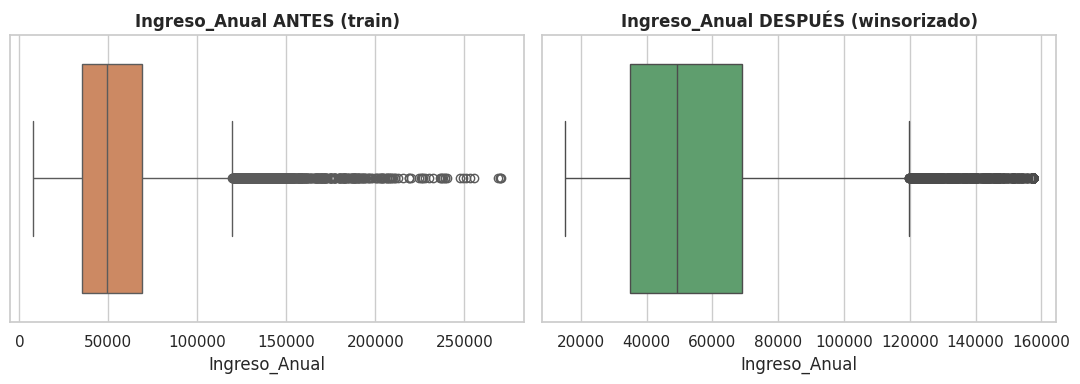

Test: filas de Ingreso_Anual por encima del p99 de train (se recortan al límite): 65


In [18]:
prep_demo = crear_preprocesador().fit(X_train)       # fit SOLO con entrenamiento
Xtr_t = pd.DataFrame(prep_demo.transform(X_train), columns=features_num)
Xte_t = pd.DataFrame(prep_demo.transform(X_test), columns=features_num)

print("Límites de winsorización aprendidos en TRAIN (p1 y p99):")
win = prep_demo.named_transformers_["num"].named_steps["winsorizer"]
display(pd.DataFrame({"p1": win.lower_, "p99": win.upper_}).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=X_train["Ingreso_Anual"], ax=axes[0], color="#DD8452")
axes[0].set_title("Ingreso_Anual ANTES (train)", fontweight="bold")
sns.boxplot(x=Xtr_t["Ingreso_Anual"], ax=axes[1], color="#55A868")
axes[1].set_title("Ingreso_Anual DESPUÉS (winsorizado)", fontweight="bold")
plt.tight_layout(); plt.show()

# Los límites salen de train y se aplican igual al test (el test puede quedar fuera de esos límites antes de recortarse)
print("Test: filas de Ingreso_Anual por encima del p99 de train (se recortan al límite):",
      int((X_test["Ingreso_Anual"] > win.upper_["Ingreso_Anual"]).sum()))

Los límites p1/p99 se aprenden **solo con train** y se aplican tal cual al test: el test no participa en ningún cálculo del preprocesamiento. Las variables conservan sus **unidades originales**, lo que permitirá leer el árbol en términos de negocio.

## 3.2 Modelo base (línea base)

`DecisionTreeClassifier` con **parámetros por defecto** (solo se fija la semilla), dentro del mismo pipeline de preprocesamiento. Sin límite de profundidad, un árbol tiende a **memorizar** el entrenamiento (overfitting); este modelo sirve como punto de comparación.

In [19]:
pipe_base = crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
pipe_base.fit(X_train, y_train)

y_pred_base = pipe_base.predict(X_test)
arbol_base = pipe_base.named_steps["clf"]
print(f"Profundidad del árbol base: {arbol_base.get_depth()} | Hojas: {arbol_base.get_n_leaves()}")

Profundidad del árbol base: 27 | Hojas: 1646


## 3.3 Modelo optimizado con `GridSearchCV`

### Hiperparámetros y justificación del espacio de búsqueda

| Hiperparámetro | Valores | ¿Por qué? |
|---|---|---|
| `max_depth` | 3, 4, 5, 6, 8, 10 | Controla la complejidad. El árbol base crece sin límite (sobreajuste). Se prueban profundidades que permiten reglas interpretables (3–6) y algo más flexibles (8–10). |
| `min_samples_leaf` | 5, 10, 20, 50 | Exige un mínimo de clientes por hoja: evita hojas que "memorizan" 1–2 impagos. |
| `min_samples_split` | 10, 20, 50 | Evita dividir nodos con pocas muestras. |
| `criterion` | gini, entropy | Los dos criterios de impureza disponibles para elegir cada división. |
| `class_weight` | None, balanced | **Clave en datos desbalanceados**: `balanced` pondera más a la clase impago (≈ 13×) para que el árbol no la ignore. |

### Validación y métrica de optimización
- **`StratifiedKFold(5, shuffle=True, random_state=29)`**: cada fold conserva el ≈ 7 % de impagos.
- El `GridSearchCV` se ajusta **sobre el pipeline completo**: en cada fold el preprocesamiento se aprende solo con la parte de entrenamiento del fold (sin leakage).
- **`refit="recall"`**: se elige la combinación con mayor *recall* de la clase Impago, porque el error más costoso (FN, \$1,5 M) es no detectar un impago. Se registran también **F1** como contrapeso: evitaría elegir un modelo que "rechaza a todos" solo para maximizar el recall. Estas son las mismas dos métricas con las que se evaluará en test (ver Fase 4).
- Se usa `random_state=29` en el árbol, en el `StratifiedKFold` y en el split.

In [20]:
param_grid = {
    "clf__max_depth": [3, 4, 5, 6, 8, 10],
    "clf__min_samples_leaf": [5, 10, 20, 50],
    "clf__min_samples_split": [10, 20, 50],
    "clf__criterion": ["gini", "entropy"],
    "clf__class_weight": [None, "balanced"],
}
n_comb = np.prod([len(v) for v in param_grid.values()])
print(f"Combinaciones: {n_comb} x 5 folds = {n_comb * 5} ajustes")

grid = GridSearchCV(
    estimator=crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    param_grid=param_grid,
    scoring={"recall": "recall", "f1": "f1"},      # métricas sobre la clase positiva (Impago = 1)
    refit="recall",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("\nMejores hiperparámetros")
print("-" * 40)
for i, (p, v) in enumerate(grid.best_params_.items(), start=1):
    print(f"Parámetro {i}: {p:<28} = {v}")
print("-" * 40)
print(f"Mejor recall (CV, clase Impago): {grid.best_score_:.4f}")

Combinaciones: 288 x 5 folds = 1440 ajustes

Mejores hiperparámetros
----------------------------------------
Parámetro 1: clf__class_weight            = balanced
Parámetro 2: clf__criterion               = gini
Parámetro 3: clf__max_depth               = 6
Parámetro 4: clf__min_samples_leaf        = 50
Parámetro 5: clf__min_samples_split       = 10
----------------------------------------
Mejor recall (CV, clase Impago): 0.7351


In [21]:
# GridSearchCV con refit ya reentrenó el mejor pipeline con TODO X_train: está listo para usarse
pipe_opt = grid.best_estimator_
y_pred_opt = pipe_opt.predict(X_test)
arbol_opt = pipe_opt.named_steps["clf"]
print(f"Profundidad del árbol optimizado: {arbol_opt.get_depth()} | Hojas: {arbol_opt.get_n_leaves()}")

Profundidad del árbol optimizado: 6 | Hojas: 52


In [22]:
# Mejores 10 configuraciones en validación cruzada (se ve el balance recall vs F1)
cv_res = pd.DataFrame(grid.cv_results_)
cols = ["param_clf__max_depth", "param_clf__min_samples_leaf", "param_clf__min_samples_split",
        "param_clf__criterion", "param_clf__class_weight", "mean_test_recall", "mean_test_f1"]
top = cv_res.sort_values("rank_test_recall").head(10)[cols]
top.columns = [c.replace("param_clf__", "") for c in top.columns]
display(top.round(4).reset_index(drop=True))

,max_depth,min_samples_leaf,min_samples_split,criterion,class_weight,mean_test_recall,mean_test_f1
0,6,50,50,gini,balanced,0.7351,0.2893
1,6,50,20,gini,balanced,0.7351,0.2893
2,6,50,10,gini,balanced,0.7351,0.2893
3,6,10,50,gini,balanced,0.7296,0.2878
4,6,5,50,gini,balanced,0.7289,0.2880
5,6,10,10,gini,balanced,0.7289,0.2883
6,6,10,20,gini,balanced,0.7289,0.2883
7,6,20,50,gini,balanced,0.7289,0.2878
8,6,20,20,gini,balanced,0.7282,0.2883
9,6,20,10,gini,balanced,0.7282,0.2883


### ¿Cambia algo la winsorización en este árbol?
Se compara, con los mejores hiperparámetros y la misma validación cruzada estratificada sobre **train**, el mismo árbol con y sin winsorización (el test no se usa para decidir).

In [23]:
mejores = {k.replace("clf__", ""): v for k, v in grid.best_params_.items()}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def prep_sin_winsor():
    return ColumnTransformer([("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), features_num)])

res = {}
for nombre, prep in [("Con winsorización", crear_preprocesador()), ("Sin winsorización", prep_sin_winsor())]:
    pipe = Pipeline([("prep", prep), ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE, **mejores))])
    r = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=["recall", "f1"])
    res[nombre] = {"Recall (CV)": r["test_recall"].mean(), "F1 (CV)": r["test_f1"].mean()}
comparacion_winsor = pd.DataFrame(res).T.round(4)
display(comparacion_winsor)

,Recall (CV),F1 (CV)
Con winsorización,0.7351,0.2893
Sin winsorización,0.7351,0.2893


La diferencia en recall es **0.0000** y en F1 **0.0000**: el desempeño es idéntico, es decir, la winsorización **no cambia de forma relevante** al árbol. Se mantiene como control de calidad de datos, sin que condicione los resultados.

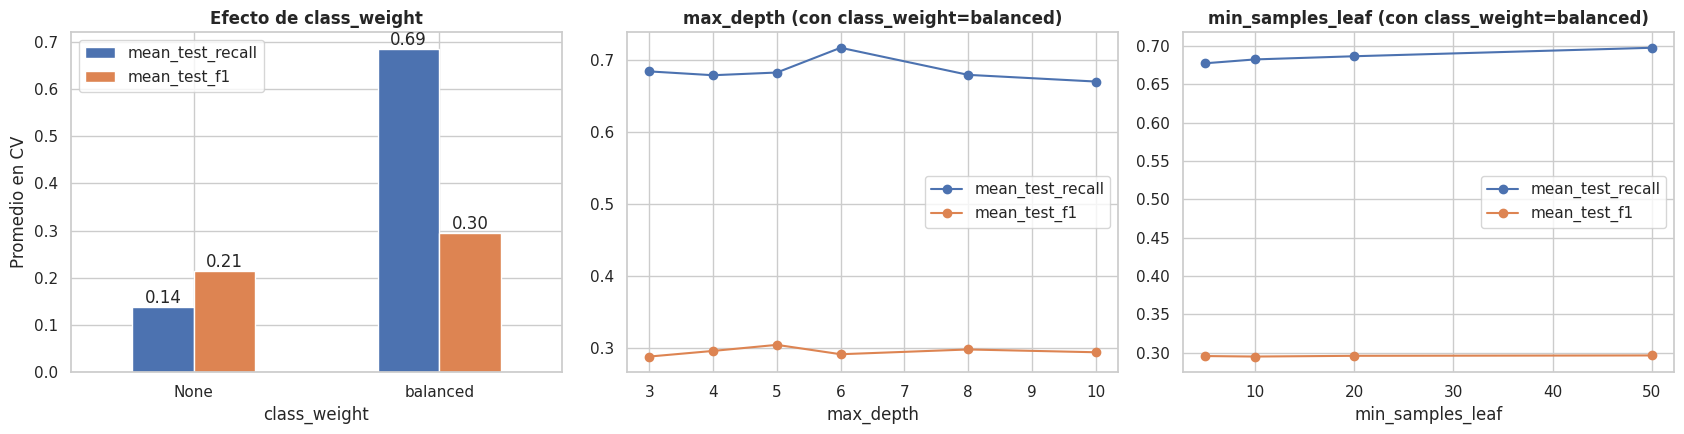

                      mean_test_recall  mean_test_f1
param_clf__criterion                                
entropy                          0.414         0.252
gini                             0.410         0.257


In [24]:
# Efecto de los hiperparámetros sobre recall y F1 (promedio en validación cruzada)
# class_weight domina el resultado, así que max_depth y min_samples_leaf se miran DENTRO de class_weight="balanced"
# (None se guarda como valor "enmascarado" en cv_results_, por eso se lee desde la lista de params)
cv_res["class_weight_str"] = [str(p["clf__class_weight"]) for p in grid.cv_results_["params"]]
bal = cv_res[cv_res["class_weight_str"] == "balanced"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

d = cv_res.groupby("class_weight_str")[["mean_test_recall", "mean_test_f1"]].mean()
d.plot(kind="bar", ax=axes[0], rot=0); axes[0].set_title("Efecto de class_weight", fontweight="bold")
axes[0].set_xlabel("class_weight"); axes[0].set_ylabel("Promedio en CV")
for c in axes[0].containers: axes[0].bar_label(c, fmt="%.2f")

d = bal.groupby("param_clf__max_depth")[["mean_test_recall", "mean_test_f1"]].mean()
d.plot(marker="o", ax=axes[1]); axes[1].set_title("max_depth (con class_weight=balanced)", fontweight="bold")
axes[1].set_xlabel("max_depth")

d = bal.groupby("param_clf__min_samples_leaf")[["mean_test_recall", "mean_test_f1"]].mean()
d.plot(marker="o", ax=axes[2]); axes[2].set_title("min_samples_leaf (con class_weight=balanced)", fontweight="bold")
axes[2].set_xlabel("min_samples_leaf")
plt.tight_layout(); plt.show()

print(cv_res.groupby("param_clf__criterion")[["mean_test_recall", "mean_test_f1"]].mean().round(3))

**Justificación de la elección (con respaldo en los gráficos):**
- **`class_weight` es el hiperparámetro decisivo:** con `balanced` el recall promedio en validación es ≈ 0,69; sin ponderar es ≈ 0,14. Sin ponderación el árbol prioriza a la clase mayoritaria (93 %) y deja pasar casi todos los impagos. Todas las mejores configuraciones usan `balanced`.
- **`max_depth`:** dentro de `balanced`, el recall se mantiene en una banda estrecha (≈ 0,67–0,72) y alcanza su máximo en **profundidad 6**; con 8–10 el árbol se complejiza sin ganar capacidad de detección (y pierde interpretabilidad). El óptimo fue **6**.
- **`min_samples_leaf`:** el recall sube levemente al exigir hojas más grandes (reglas más estables, menos memorización de unos pocos impagos); el óptimo fue **50**. El efecto sobre F1 es prácticamente nulo.
- **`criterion` y `min_samples_split`:** influyen poco (gini y entropy rinden casi igual), por lo que no condicionan la decisión.
- **Mejor combinación:** `{'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 50, 'min_samples_split': 10}`.

---
# Fase 4 — Evaluación e interpretación (conjunto de prueba)

## 4.1 Elección de las DOS métricas

Contexto: **7 % de impagos** y **costos asimétricos** (FN = \$1,5 M vs FP = \$0,2 M).

| Métrica (clase **Impago**) | Qué responde | Por qué la elegimos |
|---|---|---|
| **Recall (sensibilidad)** = VP / (VP + FN) | De todos los clientes que *sí* caerán en impago, ¿cuántos detecta el modelo? | Mide directamente el error más caro: cada FN cuesta \$1,5 M. Es la métrica principal del banco. |
| **F1-score** = media armónica de Precision y Recall | ¿Detecta impagos *sin* rechazar a demasiados clientes buenos? | Contrapeso del recall: un modelo que rechaza a todos tendría recall = 100 % pero F1 muy bajo, porque cada FP cuesta \$0,2 M y destruye negocio. Resume el equilibrio en una sola cifra y es robusta al desbalance. |

**Por qué no *accuracy*:** con 92,8 % de cumplidores, aprobar a todos da 92,8 % de accuracy y es el peor resultado posible para el banco. Se muestra en la tabla solo para evidenciar ese engaño.

In [25]:
def metricas_test(y_true, y_pred):
    return {
        "Recall (Impago)": recall_score(y_true, y_pred),
        "F1-score (Impago)": f1_score(y_true, y_pred),
        # apoyo (no son las métricas elegidas):
        "Precision (Impago)": precision_score(y_true, y_pred),
        "Accuracy": accuracy_score(y_true, y_pred),
    }

tabla_metricas = pd.DataFrame({
    "Línea base": metricas_test(y_test, y_pred_base),
    "Optimizado": metricas_test(y_test, y_pred_opt),
}).round(4)
display(tabla_metricas)

for nombre, pred in [("LÍNEA BASE", y_pred_base), ("MODELO OPTIMIZADO", y_pred_opt)]:
    print(f"\n--- Reporte de clasificación: {nombre} ---")
    print(classification_report(y_test, pred, target_names=target_names))

,Línea base,Optimizado
Recall (Impago),0.3296,0.8073
F1-score (Impago),0.3155,0.2989
Precision (Impago),0.3026,0.1834
Accuracy,0.8976,0.7288



--- Reporte de clasificación: LÍNEA BASE ---
              precision    recall  f1-score   support

   Cumplidor       0.95      0.94      0.94      4642
      Impago       0.30      0.33      0.32       358

    accuracy                           0.90      5000
   macro avg       0.63      0.64      0.63      5000
weighted avg       0.90      0.90      0.90      5000


--- Reporte de clasificación: MODELO OPTIMIZADO ---
              precision    recall  f1-score   support

   Cumplidor       0.98      0.72      0.83      4642
      Impago       0.18      0.81      0.30       358

    accuracy                           0.73      5000
   macro avg       0.58      0.77      0.57      5000
weighted avg       0.92      0.73      0.79      5000



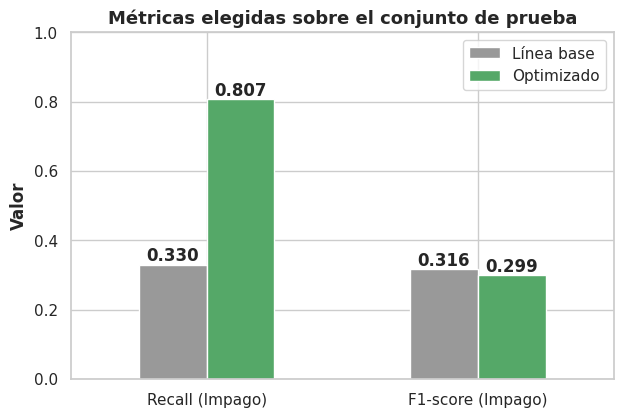

In [26]:
ax = tabla_metricas.loc[["Recall (Impago)", "F1-score (Impago)"]].plot(
    kind="bar", figsize=(7, 4.5), color=["#999999", "#55A868"], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontweight="bold")
plt.title("Métricas elegidas sobre el conjunto de prueba", fontsize=13, fontweight="bold")
plt.ylabel("Valor", fontweight="bold"); plt.ylim(0, 1)
plt.show()

**Lectura de las métricas (traducción a negocio):**
- **Recall:** pasa de **33.0%** a **80.7%**. En palabras simples: la línea base detecta solo 1 de cada 3 impagos; el modelo optimizado detecta ≈ 8 de cada 10.
- **F1-score:** pasa de **0.316** a **0.299**, es decir, se mantiene prácticamente igual (ligeramente menor). Esto se debe a que la *precision* cae (30.3% → 18.3%): el modelo marca como riesgosos a más clientes buenos. El F1 trata FP y FN como igual de graves, pero para el banco un FN cuesta 7,5 veces más; por eso la lectura correcta es: **mejoramos mucho la detección sin deteriorar el equilibrio global**, y el beneficio económico real se ve en la matriz de costos (4.2).
- **Accuracy:** baja de 89.8% a 72.9%, lo que **no** es una mala noticia: el modelo "sacrifica" aciertos fáciles sobre cumplidores para atrapar impagos, que es justamente lo que le interesa al banco.

## 4.2 Matrices de confusión

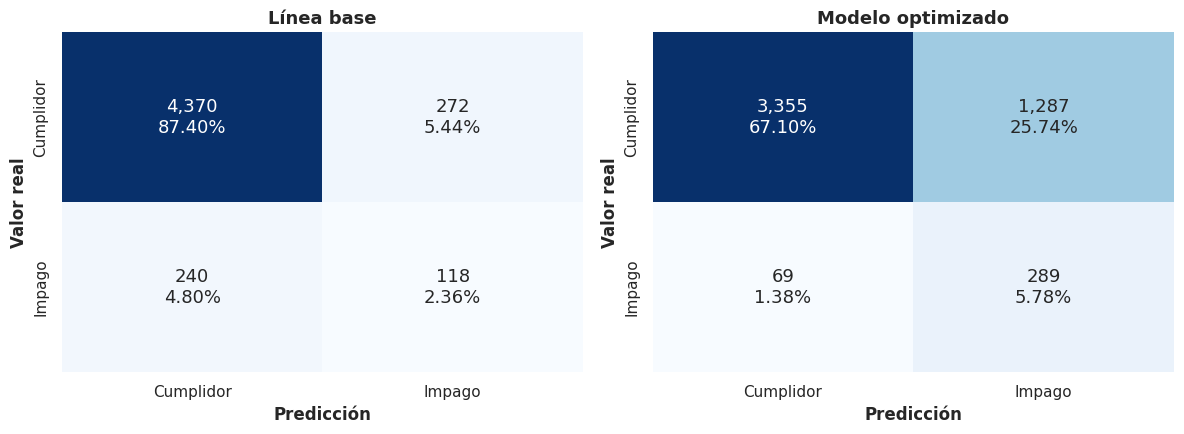

In [27]:
def ver_matriz(ax, y_true, y_pred, titulo):
    m = confusion_matrix(y_true, y_pred)
    etiquetas = np.array([f"{v:,}\n{v / m.sum():.2%}" for v in m.flatten()]).reshape(2, 2)
    sns.heatmap(m, annot=etiquetas, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=target_names, yticklabels=target_names, annot_kws={"size": 13})
    ax.set_xlabel("Predicción", fontsize=12, fontweight="bold")
    ax.set_ylabel("Valor real", fontsize=12, fontweight="bold")
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    return m

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
cm_base = ver_matriz(axes[0], y_test, y_pred_base, "Línea base")
cm_opt = ver_matriz(axes[1], y_test, y_pred_opt, "Modelo optimizado")
plt.tight_layout(); plt.show()

In [28]:
# Traducción a impacto financiero:  FN -> $1,5 M c/u ; FP -> $0,2 M c/u
filas = []
for nombre, cm in [("Línea base", cm_base), ("Optimizado", cm_opt)]:
    tn, fp, fn, tp = cm.ravel()
    filas.append({
        "Modelo": nombre,
        "VN (aprueba y paga)": tn, "FP (rechaza a buen cliente)": fp,
        "FN (aprueba y no paga)": fn, "VP (rechaza a moroso)": tp,
        "Pérdida por FN ($)": fn * COSTO_FN,
        "Costo oportunidad FP ($)": fp * COSTO_FP,
        "COSTO TOTAL ($)": fn * COSTO_FN + fp * COSTO_FP,
    })
costos = pd.DataFrame(filas).set_index("Modelo")
display(costos.style.format({c: "{:,.0f}" for c in costos.columns}))

# Referencia: aprobar a todos (sin modelo)
n_imp_test = int(y_test.sum())
costo_sin_modelo = n_imp_test * COSTO_FN
print(f"\nReferencia — sin modelo (aprobar a todos): {n_imp_test} impagos x $1.500.000 = ${costo_sin_modelo:,.0f}")
for nombre in costos.index:
    ahorro = costo_sin_modelo - costos.loc[nombre, "COSTO TOTAL ($)"]
    print(f"Ahorro vs. sin modelo — {nombre:<11}: ${ahorro:,.0f} ({ahorro / costo_sin_modelo:.1%})")

,VN (aprueba y paga),FP (rechaza a buen cliente),FN (aprueba y no paga),VP (rechaza a moroso),Pérdida por FN ($),Costo oportunidad FP ($),COSTO TOTAL ($)
Modelo,,,,,,,
Línea base,"4,370",272,240,118,"360,000,000","54,400,000","414,400,000"
Optimizado,"3,355","1,287",69,289,"103,500,000","257,400,000","360,900,000"



Referencia — sin modelo (aprobar a todos): 358 impagos x $1.500.000 = $537,000,000
Ahorro vs. sin modelo — Línea base : $122,600,000 (22.8%)
Ahorro vs. sin modelo — Optimizado : $176,100,000 (32.8%)


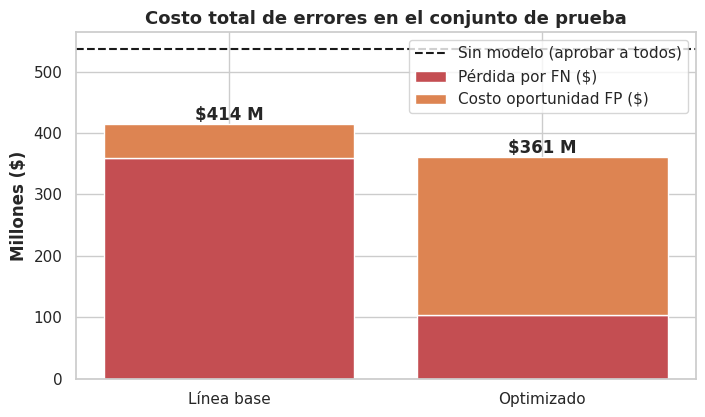

In [29]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bottom = np.zeros(2)
for col, color in [("Pérdida por FN ($)", "#C44E52"), ("Costo oportunidad FP ($)", "#DD8452")]:
    ax.bar(costos.index, costos[col] / 1e6, bottom=bottom, label=col, color=color)
    bottom += costos[col].values / 1e6
for i, tot in enumerate(bottom):
    ax.text(i, tot, f"${tot:,.0f} M", ha="center", va="bottom", fontweight="bold")
ax.axhline(costo_sin_modelo / 1e6, color="k", ls="--", label="Sin modelo (aprobar a todos)")
ax.set_ylabel("Millones ($)", fontweight="bold")
ax.set_title("Costo total de errores en el conjunto de prueba", fontsize=13, fontweight="bold")
ax.legend(); plt.show()

## 4.3 Interpretación de las matrices de confusión (contexto financiero)

> Convención: **clase positiva = Impago**. Filas = valor real, columnas = predicción.

| | Línea base | Optimizado |
|---|---|---|
| **VN** — se aprueba y el cliente paga | 4,370 | 3,355 |
| **FP** — se rechaza a un cliente que habría pagado | 272 | 1,287 |
| **FN** — se aprueba y el cliente **no paga** | 240 | 69 |
| **VP** — se rechaza a quien habría caído en impago | 118 | 289 |

### Línea base
- Detecta solo **118 de 358** impagos (recall 33.0%): deja pasar **240 impagos (FN)**, que cuestan **\$360,000,000**. Es la fuente principal de pérdida.
- Su *accuracy* (89.8%) parece alto, pero es engañoso: lo sostienen los 4,370 cumplidores bien clasificados.
- Genera **272 FP** (costo de oportunidad \$54,400,000): rechaza pocos clientes buenos, pero a cambio no protege el capital.
- Es un árbol sin límites (profundidad 27); la diferencia entre train y test (sección 4.4) revela **sobreajuste**: memoriza ejemplos en vez de aprender reglas generales.

### Modelo optimizado
- Detecta **289 de 358** impagos (recall 80.7%): los FN bajan de 240 a **69**, es decir, **171 impagos menos** que ingresan a la cartera, equivalente a **\$256,500,000** de capital protegido.
- El precio es un fuerte aumento de FP: de 272 a **1,287** (+\$203,000,000 en costo de oportunidad). Esto era esperable: `class_weight="balanced"` hace al modelo más "prudente".
- Dado que un FN cuesta 7,5 veces un FP, el intercambio **sí conviene**: el costo total pasa de **\$414,400,000** a **\$360,900,000** (-12.9%).
- Su *precision* es baja (18.3%): de cada 100 clientes rechazados por el modelo, solo ≈ 18 habrían caído en impago. Por eso el modelo debe usarse como **herramienta de alerta/priorización** (p. ej. revisión manual adicional o ajuste de condiciones) y no como rechazo automático.


## 4.4 Revisión de sobreajuste (train vs test)

Recall (Impago)         F1-score (Impago)        
Conjunto              Test   Train              Test   Train
Modelo                                                      
Línea base          0.3296  1.0000            0.3155  1.0000
Optimizado          0.8073  0.8127            0.2989  0.3105

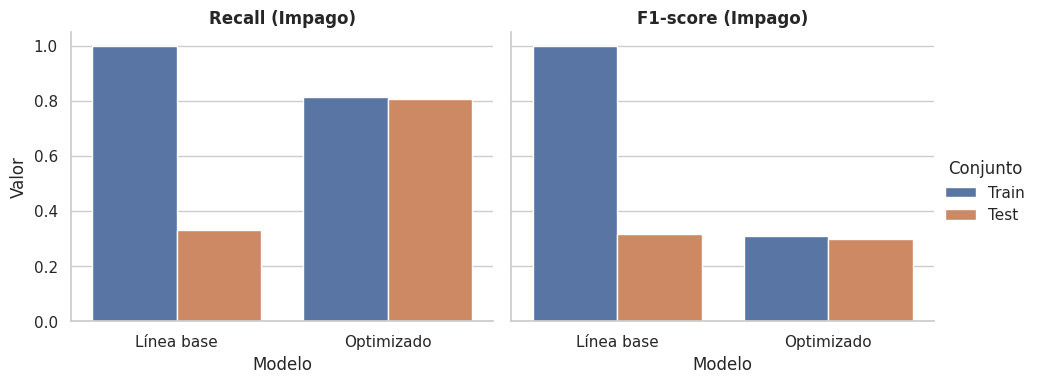

In [30]:
filas = []
for nombre, pipe in [("Línea base", pipe_base), ("Optimizado", pipe_opt)]:
    for conj, Xc, yc in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
        p = pipe.predict(Xc)
        filas.append({"Modelo": nombre, "Conjunto": conj,
                      "Recall (Impago)": recall_score(yc, p), "F1-score (Impago)": f1_score(yc, p)})
sobreajuste = pd.DataFrame(filas).round(4)
display(sobreajuste.pivot(index="Modelo", columns="Conjunto", values=["Recall (Impago)", "F1-score (Impago)"]))

g = sobreajuste.melt(id_vars=["Modelo", "Conjunto"], var_name="Métrica", value_name="Valor")
fig = sns.catplot(data=g, x="Modelo", y="Valor", hue="Conjunto", col="Métrica", kind="bar",
                  palette=["#4C72B0", "#DD8452"], height=4, aspect=1.2)
fig.set_titles("{col_name}", fontweight="bold"); fig.set(ylim=(0, 1.05))
plt.show()

- **Línea base:** recall en train = 1.00 vs en test = 0.33 (brecha de 0.67). Un árbol sin restricciones **memoriza** el entrenamiento → **sobreajuste claro**: lo que "aprendió" no se generaliza.
- **Optimizado:** recall train = 0.81 vs test = 0.81 (brecha de 0.01). La brecha es mucho menor: el modelo **generaliza** y sus resultados en producción serían más parecidos a los que reportamos.

## 4.5 Interpretabilidad: ¿qué variables mueven el riesgo?

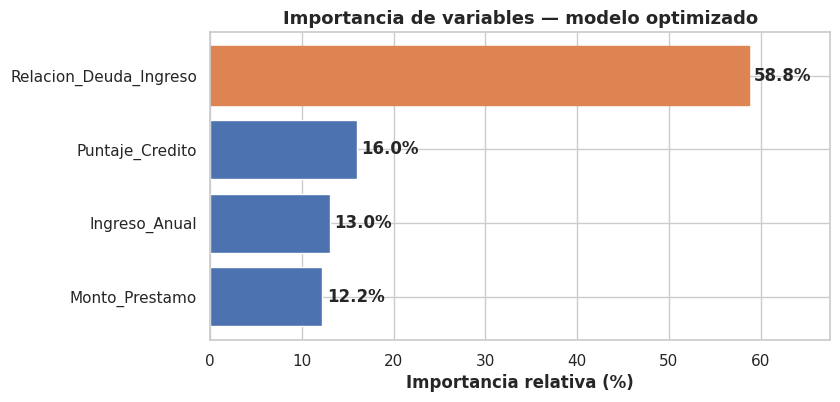

In [31]:
nombres = pipe_opt.named_steps["prep"].get_feature_names_out()
nombres = [n.replace("num__", "") for n in nombres]
imp = pd.DataFrame({"Variable": nombres, "Importancia": arbol_opt.feature_importances_}).sort_values("Importancia")

plt.figure(figsize=(8, 4))
bars = plt.barh(imp["Variable"], imp["Importancia"] * 100, color="#4C72B0")
bars[-1].set_color("#DD8452")
for b in bars:
    plt.text(b.get_width() + 0.5, b.get_y() + b.get_height() / 2, f"{b.get_width():.1f}%", va="center", fontweight="bold")
plt.xlabel("Importancia relativa (%)", fontweight="bold")
plt.title("Importancia de variables — modelo optimizado", fontsize=13, fontweight="bold")
plt.xlim(0, imp["Importancia"].max() * 100 * 1.15)
plt.show()

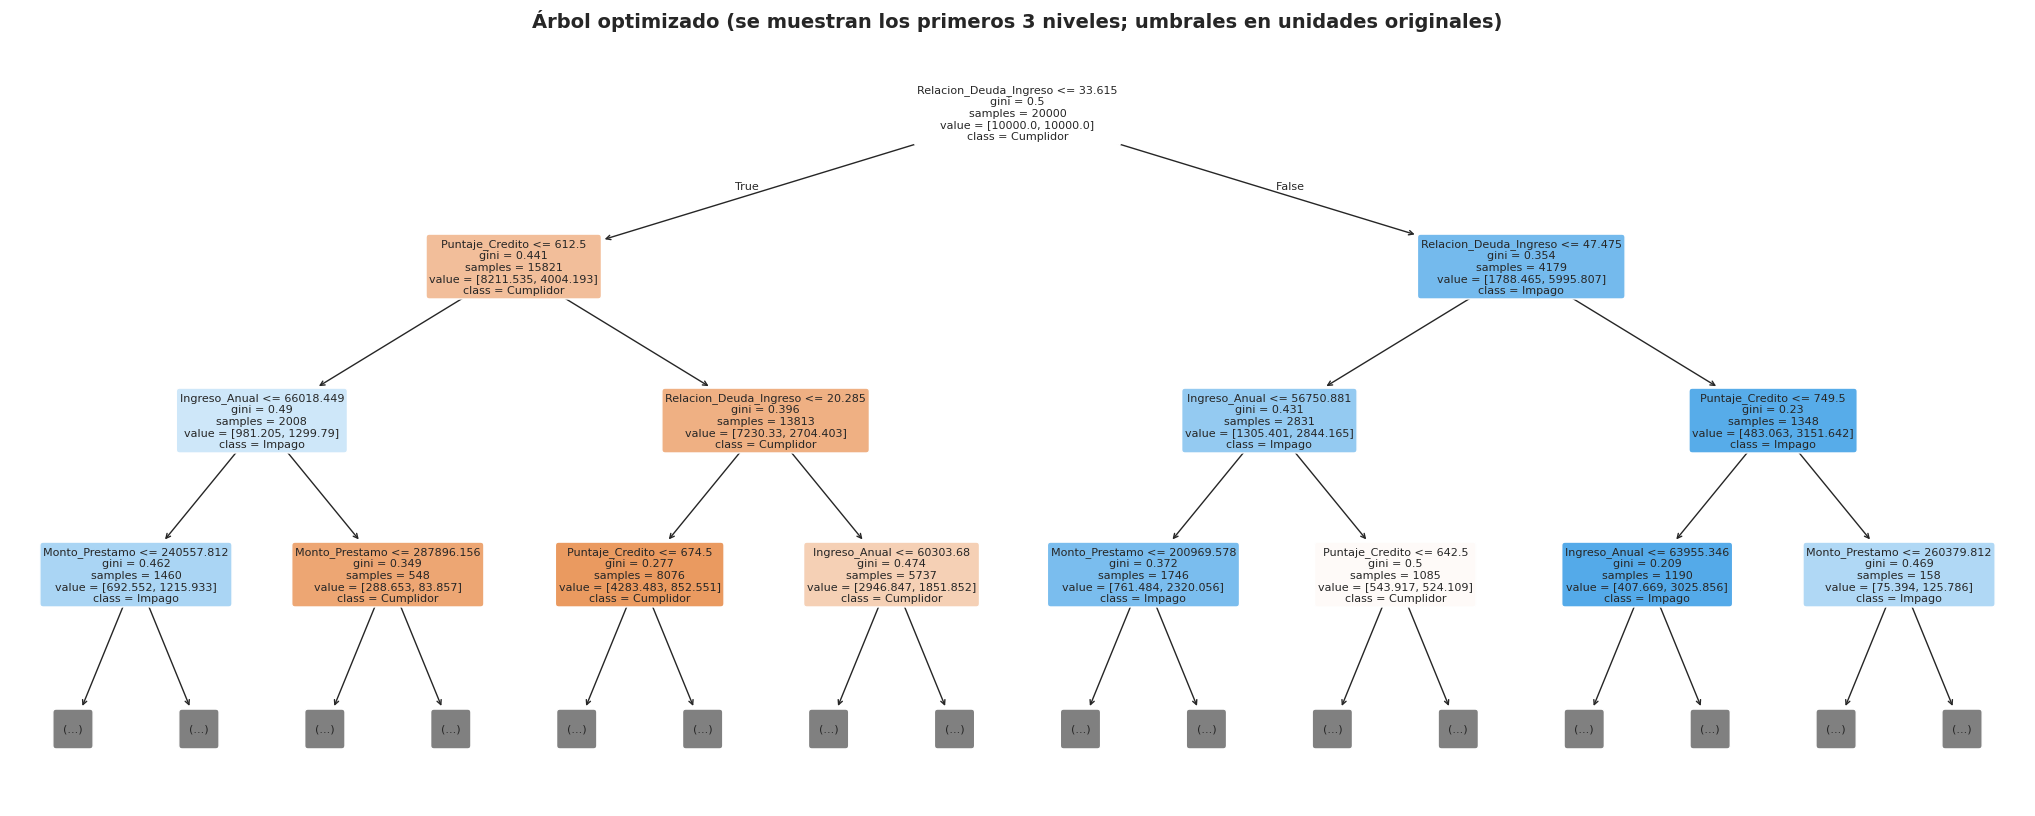

In [32]:
plt.figure(figsize=(26, 10))
plot_tree(arbol_opt, feature_names=nombres, class_names=target_names,
          filled=True, rounded=True, fontsize=8, max_depth=3)
plt.title("Árbol optimizado (se muestran los primeros 3 niveles; umbrales en unidades originales)", fontsize=14, fontweight="bold")
plt.show()

La variable más influyente es **Relacion_Deuda_Ingreso** (58.8% de la importancia), seguida de **Puntaje_Credito** (16.0%), coherente con el EDA (mayor correlación con el impago). Para el negocio: el **nivel de endeudamiento** y la **solvencia previa** son las señales más claras de alerta al evaluar una solicitud.

**Cómo leer el árbol:** al no escalar las variables, los cortes están en unidades reales; el primer corte separa a los clientes según si su DTI supera ≈ 33,6 %. Los valores `value = [a, b]` de cada nodo están ponderados por `class_weight="balanced"` (por eso el nodo raíz muestra 10.000 y 10.000 y no la proporción real de ≈ 93 % / 7 %); sirven para comparar la composición relativa entre nodos.

## Complemento: curva ROC

La curva ROC muestra, para todos los umbrales de decisión posibles, la relación entre la **tasa de verdaderos positivos** (TPR = recall: impagos detectados) y la **tasa de falsos positivos** (FPR: buenos clientes rechazados). El **AUC** resume la capacidad del modelo para ordenar a los clientes de mayor a menor riesgo (0,5 = azar, 1 = perfecto). Los puntos marcados son la operación real de cada modelo (umbral de decisión por defecto), la misma que muestran las matrices de confusión.

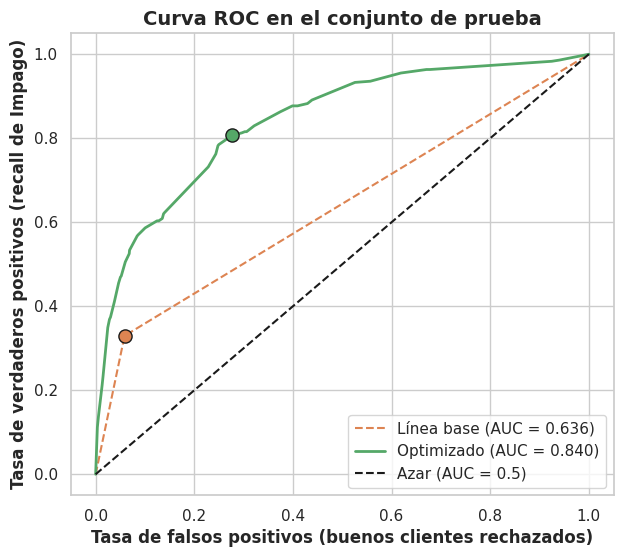

ROC-AUC línea base: 0.6355
ROC-AUC optimizado: 0.8402


In [36]:
# Probabilidades de impago (clase 1) sobre el conjunto de prueba
proba_base = pipe_base.predict_proba(X_test)[:, 1]
proba_opt = pipe_opt.predict_proba(X_test)[:, 1]

auc_base = roc_auc_score(y_test, proba_base)
auc_opt = roc_auc_score(y_test, proba_opt)

fpr_b, tpr_b, _ = roc_curve(y_test, proba_base)
fpr_o, tpr_o, _ = roc_curve(y_test, proba_opt)

# Punto de operación real de cada modelo (sale de la matriz de confusión)
tn_b, fp_b, fn_b, tp_b = cm_base.ravel()
tn_o, fp_o, fn_o, tp_o = cm_opt.ravel()

plt.figure(figsize=(7, 6))
plt.plot(fpr_b, tpr_b, linestyle="--", color="#DD8452", label=f"Línea base (AUC = {auc_base:.3f})")
plt.plot(fpr_o, tpr_o, color="#55A868", linewidth=2, label=f"Optimizado (AUC = {auc_opt:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")

plt.scatter(fp_b / (fp_b + tn_b), tp_b / (tp_b + fn_b), color="#DD8452", s=90, zorder=5, edgecolor="k")
plt.scatter(fp_o / (fp_o + tn_o), tp_o / (tp_o + fn_o), color="#55A868", s=90, zorder=5, edgecolor="k")

plt.xlabel("Tasa de falsos positivos (buenos clientes rechazados)", fontsize=12, fontweight="bold")
plt.ylabel("Tasa de verdaderos positivos (recall de Impago)", fontsize=12, fontweight="bold")
plt.title("Curva ROC en el conjunto de prueba", fontsize=14, fontweight="bold")
plt.legend(loc="lower right")
plt.show()

print(f"ROC-AUC línea base: {auc_base:.4f}")
print(f"ROC-AUC optimizado: {auc_opt:.4f}")

### Conclusión de la curva ROC

- El modelo optimizado alcanza un **ROC-AUC de 0,840 frente a 0,636 de la línea base**. En términos de negocio, si se toma al azar un cliente que cayó en impago y uno que cumplió, el modelo optimizado asigna mayor riesgo al moroso en ≈ 84 % de los casos (la línea base, en ≈ 64 %, apenas mejor que el azar).
- La curva de la línea base es casi una recta con un único punto de operación: al no tener límite de profundidad, el árbol memoriza y entrega probabilidades casi siempre 0 o 1, por lo que no permite graduar el nivel de riesgo. El modelo optimizado, con hojas más grandes, produce probabilidades graduadas que sí ordenan a los clientes por riesgo.
- El punto marcado del modelo optimizado (≈ 28 % de FPR y ≈ 81 % de recall) corresponde al umbral por defecto. Más allá de ese punto la curva se aplana: detectar el 20 % restante de impagos exigiría rechazar a muchos más clientes buenos. Para el banco esto confirma que el compromiso elegido es razonable, y que ajustar el umbral de decisión según los costos (\$1,5 M por FN vs \$0,2 M por FP) es una vía concreta de mejora.
- Como el AUC evalúa el ordenamiento y no un umbral particular, complementa a Recall y F1 sin reemplazarlos: las decisiones de aprobación siguen evaluándose con las métricas elegidas en la sección 4.1.